# 01b. DART 업종·자산 수집

`data/raw/company_master.csv`의 기업-연도별 행에 OpenDART 기업개황의 업종코드와 해당 사업연도 총자산을 붙여 `data/processed/company_controls.csv`로 저장합니다.

- 기업 식별: 입력 회사명에 대응하는 `stock_code`를 우선 사용해 DART `corp_code`를 찾습니다. 종목코드가 없을 때만 정규화한 회사명으로 보완합니다.
- 업종: OpenDART 기업개황 API는 업종 **명칭**이 아니라 표준산업분류 업종코드(`induty_code`)를 제공합니다. 기존 마스터의 업종명이 있으면 유지하고, 없으면 `KSIC_<업종코드>` 그룹을 만들어 회귀의 업종 더미로 사용할 수 있게 합니다.
- 자산: 사업보고서(`reprt_code=11011`)의 재무상태표에서 연결재무제표(`CFS`)를 우선 사용하고, 없으면 별도재무제표(`OFS`)로 보완합니다.
- API 키: 프로젝트 루트의 `.env`에 `DART_API_KEY=...`를 설정합니다.

**해석 가이드**: 최종 검증에서 `status == OK` 비율, `assets_fs_div`의 CFS/OFS 구성, `industry_source`의 기존 명칭/코드 대체 구성을 함께 확인합니다.

## 1. 환경 설정

프로젝트 루트를 자동 탐지하고 `.env`의 API 키를 읽습니다. API 키 원문은 출력하지 않습니다.

In [1]:
import io
import json
import math
import os
import re
import time
import zipfile
import xml.etree.ElementTree as ET
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd
import requests


def find_project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / 'pyproject.toml').exists() and (candidate / 'data').exists():
            return candidate
    return Path.cwd()


def load_env_file(path: Path) -> None:
    if not path.exists():
        return
    for raw_line in path.read_text(encoding='utf-8').splitlines():
        line = raw_line.strip()
        if not line or line.startswith('#') or '=' not in line:
            continue
        key, value = line.split('=', 1)
        os.environ.setdefault(key.strip(), value.strip().strip('"').strip("'"))


PROJECT_ROOT = find_project_root()
load_env_file(PROJECT_ROOT / '.env')

API_KEY = os.getenv('DART_API_KEY') or os.getenv('OPENDART_API_KEY')
if not API_KEY:
    raise RuntimeError('.env에 DART_API_KEY 또는 OPENDART_API_KEY를 설정하세요.')

OPENDART_BASE = 'https://opendart.fss.or.kr/api'
REQUEST_TIMEOUT = 60
SLEEP_BETWEEN_CALLS = 0.25

RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

COMPANY_MASTER_PATH = RAW_DIR / 'company_master.csv'
CORP_CODE_PATH = RAW_DIR / 'CORPCODE.xml'
OUTPUT_PATH = PROCESSED_DIR / 'company_controls.csv'

print('프로젝트 루트:', PROJECT_ROOT)
print('입력 CSV:', COMPANY_MASTER_PATH)
print('출력 CSV:', OUTPUT_PATH)
print('API 키 로딩:', 'OK' if API_KEY else 'FAIL')

프로젝트 루트: /Users/home1/esg-dart-project
입력 CSV: /Users/home1/esg-dart-project/data/raw/company_master.csv
출력 CSV: /Users/home1/esg-dart-project/data/processed/company_controls.csv
API 키 로딩: OK


## 2. 입력 데이터 확인

종목코드는 앞자리 `0`이 사라지지 않도록 문자열로 읽습니다. 아래 표와 막대그래프로 연도별 행 수와 기존 업종 결측을 확인합니다.

**정상 기준**: `stock_code` 결측이 없고, 각 사업연도의 행 수가 예상과 일치해야 합니다.

,metric,value
0,기업-연도 행 수,381
1,고유 회사명 수,133
2,고유 종목코드 수,127
3,종목코드 결측,0
4,기존 업종명 결측,297


,company_name,stock_code,industry,fiscal_year
0,삼성전자,005930,전기전자,2022
1,삼성전자,005930,전기전자,2023


/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_72407/868504899.py:24: UserWarning: Glyph 49324 (\N{HANGUL SYLLABLE SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_72407/868504899.py:24: UserWarning: Glyph 50629 (\N{HANGUL SYLLABLE EOB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_72407/868504899.py:24: UserWarning: Glyph 50672 (\N{HANGUL SYLLABLE YEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_72407/868504899.py:24: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_72407/868504899.py:24: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_

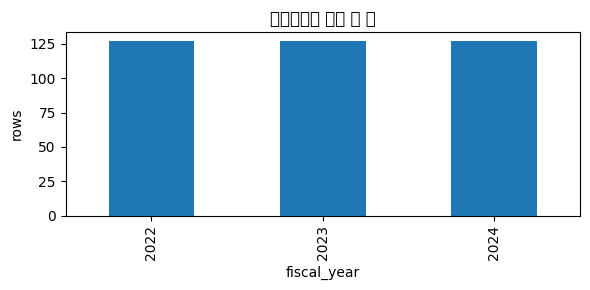

해석: 종목코드 결측이 0인지, 연도별 행 수가 균형적인지 확인하세요.


In [2]:
def load_company_master(path: Path = COMPANY_MASTER_PATH) -> pd.DataFrame:
    df = pd.read_csv(path, dtype={'stock_code': 'string', 'corp_code': 'string', 'rcept_no': 'string'})
    df['stock_code'] = df['stock_code'].str.replace(r'\.0$', '', regex=True).str.zfill(6)
    df['fiscal_year'] = pd.to_numeric(df['fiscal_year'], errors='raise').astype(int)
    return df


company_master = load_company_master()
input_summary = pd.DataFrame({
    'metric': ['기업-연도 행 수', '고유 회사명 수', '고유 종목코드 수', '종목코드 결측', '기존 업종명 결측'],
    'value': [
        len(company_master),
        company_master['company_name'].nunique(),
        company_master['stock_code'].nunique(),
        int(company_master['stock_code'].isna().sum()),
        int(company_master['industry'].fillna('').str.strip().eq('').sum()),
    ],
})
display(input_summary)
display(company_master[['company_name', 'stock_code', 'industry', 'fiscal_year']].head(2))

ax = company_master.groupby('fiscal_year').size().plot.bar(figsize=(6, 3), title='사업연도별 입력 행 수')
ax.set_ylabel('rows')
plt.tight_layout()
plt.show()

print('해석: 종목코드 결측이 0인지, 연도별 행 수가 균형적인지 확인하세요.')

## 3. DART 공통 함수와 기업코드 매핑

`corpCode.xml`은 최초 한 번만 내려받아 캐시합니다. 입력 행은 종목코드로 매핑하고, 종목코드가 없는 예외 행에 한해 회사명 매핑을 사용합니다.

In [3]:
def opendart_get_json(path: str, params: dict[str, Any], retries: int = 2) -> dict[str, Any]:
    request_params = {'crtfc_key': API_KEY, **params}
    last_error: Exception | None = None
    for attempt in range(retries + 1):
        try:
            response = requests.get(f'{OPENDART_BASE}/{path}', params=request_params, timeout=REQUEST_TIMEOUT)
            response.raise_for_status()
            return response.json()
        except (requests.RequestException, ValueError) as exc:
            last_error = exc
            if attempt < retries:
                time.sleep(1.5 * (attempt + 1))
    raise RuntimeError(f'OpenDART {path} 호출 실패: {last_error}')


def download_corp_code_xml(force: bool = False) -> Path:
    if CORP_CODE_PATH.exists() and not force:
        print('기업코드 캐시 사용:', CORP_CODE_PATH)
        return CORP_CODE_PATH
    response = requests.get(f'{OPENDART_BASE}/corpCode.xml', params={'crtfc_key': API_KEY}, timeout=REQUEST_TIMEOUT)
    response.raise_for_status()
    if response.content[:2] != b'PK':
        raise RuntimeError(f'corpCode.xml 응답이 ZIP이 아닙니다: {response.content[:200]!r}')
    with zipfile.ZipFile(io.BytesIO(response.content)) as zf:
        zf.extract('CORPCODE.xml', path=CORP_CODE_PATH.parent)
    print('기업코드 저장:', CORP_CODE_PATH)
    return CORP_CODE_PATH


def normalize_company_name(value: Any) -> str:
    text = '' if pd.isna(value) else str(value)
    return re.sub(r'[^0-9A-Za-z가-힣]', '', text).lower()


def build_corp_lookups() -> tuple[dict[str, str], dict[str, str]]:
    tree = ET.parse(download_corp_code_xml())
    stock_candidates: dict[str, dict[str, str]] = {}
    name_candidates: dict[str, dict[str, str]] = {}
    for item in tree.getroot().findall('list'):
        corp_code = (item.findtext('corp_code') or '').strip()
        corp_name = (item.findtext('corp_name') or '').strip()
        stock_code = (item.findtext('stock_code') or '').strip()
        modify_date = (item.findtext('modify_date') or '').strip()
        if not corp_code:
            continue
        if stock_code:
            stock_code = stock_code.zfill(6)
            previous = stock_candidates.get(stock_code)
            if previous is None or modify_date > previous['modify_date']:
                stock_candidates[stock_code] = {'corp_code': corp_code, 'modify_date': modify_date}
        name_key = normalize_company_name(corp_name)
        previous = name_candidates.get(name_key)
        if name_key and (previous is None or modify_date > previous['modify_date']):
            name_candidates[name_key] = {'corp_code': corp_code, 'modify_date': modify_date}
    stock_lookup = {key: value['corp_code'] for key, value in stock_candidates.items()}
    name_lookup = {key: value['corp_code'] for key, value in name_candidates.items()}
    return stock_lookup, name_lookup


stock_to_corp, name_to_corp = build_corp_lookups()
mapped_count = company_master['stock_code'].map(stock_to_corp).notna().sum()
print(f'전체 상장 종목 매핑: {len(stock_to_corp):,}')
print(f'입력 종목코드 매핑: {mapped_count:,}/{len(company_master):,}')
display(company_master[['company_name', 'stock_code']].head(2).assign(corp_code=lambda x: x['stock_code'].map(stock_to_corp)))
print('해석: 입력 종목코드 매핑 수가 전체 입력 행 수와 같으면 정상입니다.')

기업코드 캐시 사용: /Users/home1/esg-dart-project/data/raw/CORPCODE.xml
전체 상장 종목 매핑: 3,965
입력 종목코드 매핑: 381/381


,company_name,stock_code,corp_code
0,삼성전자,005930,00126380
1,삼성전자,005930,00126380


해석: 입력 종목코드 매핑 수가 전체 입력 행 수와 같으면 정상입니다.


## 4. 업종과 총자산 조회

기업개황(`company.json`)에서 DART 업종코드를 읽고, 단일회사 전체 재무제표(`fnlttSinglAcntAll.json`)에서 총자산을 찾습니다.

**자산 선택 규칙**: `CFS → OFS` 순서로 조회하고, 재무상태표(`BS`)의 `ifrs-full_Assets`를 가장 먼저 선택합니다. 표준 계정 ID가 없는 예외는 계정명 `자산총계`로 보완합니다.

In [4]:
PROFILE_CACHE: dict[str, dict[str, Any]] = {}
ASSET_ACCOUNT_PRIORITY = {
    'ifrs-full_Assets': 0,
    'ifrs_Assets': 1,
    'dart_Assets': 2,
}


def resolve_corp_code(row: pd.Series) -> tuple[str | None, str]:
    stock_code = '' if pd.isna(row.get('stock_code')) else str(row.get('stock_code')).zfill(6)
    if stock_code in stock_to_corp:
        return stock_to_corp[stock_code], 'stock_code'
    name_key = normalize_company_name(row.get('company_name'))
    if name_key in name_to_corp:
        return name_to_corp[name_key], 'company_name'
    return None, 'not_found'


def fetch_company_profile(corp_code: str) -> dict[str, Any]:
    if corp_code not in PROFILE_CACHE:
        payload = opendart_get_json('company.json', {'corp_code': corp_code})
        if payload.get('status') != '000':
            raise RuntimeError(f'company.json 오류: {payload.get("status")} {payload.get("message")}')
        PROFILE_CACHE[corp_code] = payload
        time.sleep(SLEEP_BETWEEN_CALLS)
    return PROFILE_CACHE[corp_code]


def parse_amount(value: Any) -> int | None:
    if value is None or pd.isna(value):
        return None
    text = str(value).replace(',', '').strip()
    if not text or text == '-':
        return None
    try:
        return int(text)
    except ValueError:
        return None


def select_assets_row(accounts: list[dict[str, Any]]) -> dict[str, Any] | None:
    candidates = []
    for account in accounts:
        if account.get('sj_div') != 'BS':
            continue
        amount = parse_amount(account.get('thstrm_amount'))
        if amount is None:
            continue
        account_id = account.get('account_id') or ''
        account_nm = re.sub(r'\s+', '', account.get('account_nm') or '')
        if account_id in ASSET_ACCOUNT_PRIORITY:
            priority = ASSET_ACCOUNT_PRIORITY[account_id]
        elif account_nm == '자산총계':
            priority = 10
        else:
            continue
        candidates.append((priority, account))
    return min(candidates, key=lambda item: item[0])[1] if candidates else None


def fetch_assets(corp_code: str, fiscal_year: int) -> dict[str, Any]:
    errors = []
    for fs_div in ('CFS', 'OFS'):
        payload = opendart_get_json('fnlttSinglAcntAll.json', {
            'corp_code': corp_code,
            'bsns_year': str(fiscal_year),
            'reprt_code': '11011',
            'fs_div': fs_div,
        })
        time.sleep(SLEEP_BETWEEN_CALLS)
        status = payload.get('status')
        if status == '000':
            account = select_assets_row(payload.get('list', []))
            if account:
                return {
                    'assets': parse_amount(account.get('thstrm_amount')),
                    'assets_fs_div': fs_div,
                    'assets_account_id': account.get('account_id', ''),
                    'assets_account_nm': account.get('account_nm', ''),
                }
            errors.append(f'{fs_div}: 자산총계 계정 없음')
        elif status in {'013', '014'}:
            errors.append(f'{fs_div}: 재무제표 없음({status})')
        else:
            errors.append(f'{fs_div}: {status} {payload.get("message", "")}'.strip())
    raise RuntimeError('; '.join(errors))


print('조회 함수 준비 완료')
print('해석: 다음 단건 테스트에서 업종코드, 자산, CFS/OFS 구분을 확인하세요.')

조회 함수 준비 완료
해석: 다음 단건 테스트에서 업종코드, 자산, CFS/OFS 구분을 확인하세요.


## 5. 단건 테스트

전체 실행 전에 삼성전자 2024년 한 행으로 API 응답을 확인합니다. 네트워크 호출이 발생합니다.

**정상 기준**: `status=OK`, `dart_industry_code` 존재, `assets > 0`, `log_assets` 존재.

,0
company_name,삼성전자
corp_code,00126380
corp_code_source,stock_code
stock_code,005930
fiscal_year,2024
existing_industry,전기전자
industry,전기전자
dart_industry_code,264
industry_source,company_master_name
assets,514531948000000


/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_72407/3528352883.py:45: UserWarning: Glyph 49340 (\N{HANGUL SYLLABLE SAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_72407/3528352883.py:45: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_72407/3528352883.py:45: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_72407/3528352883.py:45: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_72407/3528352883.py:45: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipyk

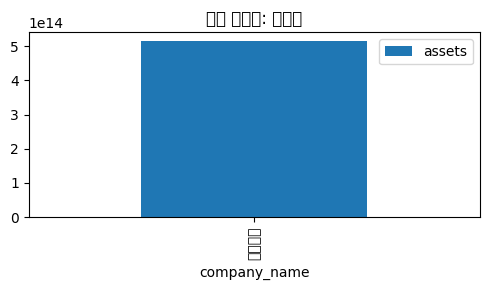

해석: status가 OK이고 assets가 양수인지, 연결재무제표가 있으면 assets_fs_div가 CFS인지 확인하세요.


In [5]:
def enrich_row(row: pd.Series) -> dict[str, Any]:
    corp_code, corp_code_source = resolve_corp_code(row)
    base = {
        'company_name': row.get('company_name', ''),
        'corp_code': corp_code or '',
        'corp_code_source': corp_code_source,
        'stock_code': str(row.get('stock_code', '')).zfill(6),
        'fiscal_year': int(row['fiscal_year']),
        'existing_industry': '' if pd.isna(row.get('industry')) else str(row.get('industry')).strip(),
    }
    if not corp_code:
        return {**base, 'industry': '', 'dart_industry_code': '', 'industry_source': 'not_found',
                'assets': None, 'log_assets': None, 'assets_fs_div': '', 'assets_account_id': '',
                'assets_account_nm': '', 'status': 'FAIL', 'error': 'corp_code를 찾지 못했습니다.'}
    try:
        profile = fetch_company_profile(corp_code)
        dart_industry_code = str(profile.get('induty_code') or '').strip()
        existing_industry = base['existing_industry']
        industry = existing_industry or (f'KSIC_{dart_industry_code}' if dart_industry_code else '')
        industry_source = 'company_master_name' if existing_industry else ('dart_industry_code' if dart_industry_code else 'not_found')
        asset_result = fetch_assets(corp_code, int(row['fiscal_year']))
        assets = asset_result['assets']
        return {
            **base,
            'industry': industry,
            'dart_industry_code': dart_industry_code,
            'industry_source': industry_source,
            **asset_result,
            'log_assets': math.log(assets) if assets and assets > 0 else None,
            'status': 'OK',
            'error': '',
        }
    except Exception as exc:
        return {**base, 'industry': '', 'dart_industry_code': '', 'industry_source': 'error',
                'assets': None, 'log_assets': None, 'assets_fs_div': '', 'assets_account_id': '',
                'assets_account_nm': '', 'status': 'FAIL', 'error': str(exc)}


sample_input = company_master[
    (company_master['stock_code'] == '005930') & (company_master['fiscal_year'] == 2024)
].iloc[0]
sample_result = pd.DataFrame([enrich_row(sample_input)])
display(sample_result.T)
sample_result.plot.bar(x='company_name', y='assets', figsize=(5, 3), title='단건 테스트: 총자산')
plt.tight_layout()
plt.show()
print('해석: status가 OK이고 assets가 양수인지, 연결재무제표가 있으면 assets_fs_div가 CFS인지 확인하세요.')

## 6. 전체 수집과 CSV 저장

전체 기업-연도를 순회합니다. 20행마다 중간 결과를 CSV로 저장하므로 실행이 중단되어도 진행 결과를 확인할 수 있습니다.

**주의**: OpenDART API 호출이 발생합니다. 완료 후 실패 행은 `error` 열에서 원인을 확인합니다.

In [6]:
OUTPUT_COLUMNS = [
    'company_name', 'corp_code', 'corp_code_source', 'stock_code', 'fiscal_year',
    'industry', 'existing_industry', 'dart_industry_code', 'industry_source',
    'assets', 'log_assets', 'assets_fs_div', 'assets_account_id', 'assets_account_nm',
    'status', 'error',
]


def collect_company_controls(df: pd.DataFrame = company_master) -> pd.DataFrame:
    results: list[dict[str, Any]] = []
    total = len(df)
    for offset, (_, row) in enumerate(df.iterrows(), start=1):
        result = enrich_row(row)
        results.append(result)
        print(f'{offset:03d}/{total} {result["stock_code"]} {result["fiscal_year"]} '
              f'{result["company_name"]}: {result["status"]} {result["error"]}')
        if offset % 20 == 0 or offset == total:
            pd.DataFrame(results, columns=OUTPUT_COLUMNS).to_csv(OUTPUT_PATH, index=False, encoding='utf-8-sig')
    return pd.DataFrame(results, columns=OUTPUT_COLUMNS)


controls_df = collect_company_controls()
print('저장 완료:', OUTPUT_PATH)
display(controls_df.head(2))
print('해석: FAIL 행이 있더라도 CSV는 저장됩니다. 다음 셀에서 실패 사유를 확인하세요.')

001/381 005930 2022 삼성전자: OK 
002/381 005930 2023 삼성전자: OK 
003/381 005930 2024 삼성전자: OK 
004/381 001460 2022 BYC: OK 
005/381 001460 2023 BYC: OK 
006/381 001460 2024 BYC: OK 
007/381 005380 2022 현대자동차: OK 
008/381 005380 2023 현대자동차: OK 
009/381 005380 2024 현대자동차: OK 
010/381 000120 2022 CJ대한통운: OK 
011/381 000120 2023 CJ대한통운: OK 
012/381 000120 2024 CJ대한통운: OK 
013/381 097950 2022 CJ제일제당: OK 
014/381 097950 2023 CJ제일제당: OK 
015/381 097950 2024 CJ제일제당: OK 
016/381 001040 2022 CJ: OK 
017/381 001040 2023 CJ: OK 
018/381 001040 2024 CJ: OK 
019/381 035760 2022 CJ ENM: OK 
020/381 035760 2023 CJ ENM: OK 
021/381 035760 2024 CJ ENM: OK 
022/381 282330 2022 BGF리테일: OK 
023/381 282330 2023 BGF리테일: OK 
024/381 282330 2024 BGF리테일: OK 
025/381 051500 2022 CJ프레시웨이: OK 
026/381 051500 2023 CJ프레시웨이: OK 
027/381 051500 2024 CJ프레시웨이: OK 
028/381 000660 2022 SK하이닉스: OK 
029/381 000660 2023 SK하이닉스: OK 
030/381 000660 2024 SK하이닉스: OK 
031/381 035420 2022 NAVER: OK 
032/381 035420 2023 NAVER: OK 
033/3

,company_name,corp_code,corp_code_source,stock_code,fiscal_year,industry,existing_industry,dart_industry_code,industry_source,assets,log_assets,assets_fs_div,assets_account_id,assets_account_nm,status,error
0,삼성전자,00126380,stock_code,005930,2022,전기전자,전기전자,264,company_master_name,4.484245e+14,33.736761,CFS,ifrs-full_Assets,자산총계,OK,
1,삼성전자,00126380,stock_code,005930,2023,전기전자,전기전자,264,company_master_name,4.559060e+14,33.753308,CFS,ifrs-full_Assets,자산총계,OK,


해석: FAIL 행이 있더라도 CSV는 저장됩니다. 다음 셀에서 실패 사유를 확인하세요.


## 7. 결과 검증

저장된 CSV를 다시 읽어 성공률, 업종 출처, 연결/별도재무제표 비율, 자산 분포와 실패 사유를 확인합니다.

**PASS 기준**: 분석에 사용할 행의 `industry`, `assets`, `log_assets`가 채워져 있어야 합니다. 일부 `OFS`는 연결재무제표가 없는 기업에서 정상일 수 있습니다.

,metric,value
0,전체 행,381
1,성공 행,363
2,실패 행,18
3,industry 결측,18
4,assets 결측,18
5,log_assets 결측,18


,company_name,fiscal_year,industry,dart_industry_code,assets,log_assets,assets_fs_div,status
0,삼성전자,2022,전기전자,264,4.484245e+14,33.736761,CFS,OK
1,삼성전자,2023,전기전자,264,4.559060e+14,33.753308,CFS,OK


/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_72407/143384423.py:22: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_72407/143384423.py:22: UserWarning: Glyph 51665 (\N{HANGUL SYLLABLE JIB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_72407/143384423.py:22: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_72407/143384423.py:22: UserWarning: Glyph 53468 (\N{HANGUL SYLLABLE TAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_72407/143384423.py:22: UserWarning: Glyph 50629 (\N{HANGUL SYLLABLE EOB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/y7/w247tcfd5q3bmlq5v2hz_thw0000gn/T/ipykernel_7

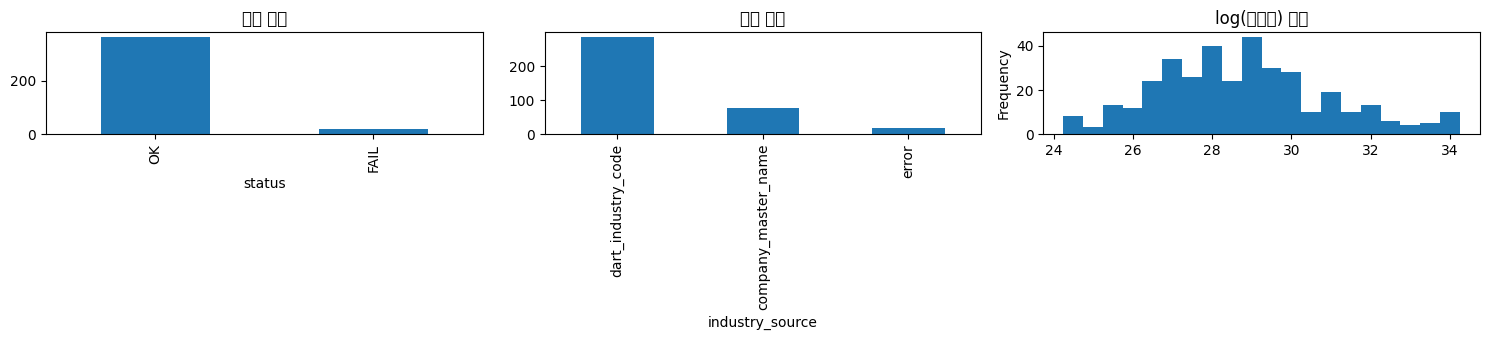

REVIEW REQUIRED: 실패 18행을 확인하세요.


,company_name,stock_code,fiscal_year,error
63,하나금융지주,086790,2022,CFS: 재무제표 없음(013); OFS: 재무제표 없음(013)
66,신한지주,055550,2022,CFS: 재무제표 없음(013); OFS: 재무제표 없음(013)
69,KB금융지주,105560,2022,CFS: 재무제표 없음(013); OFS: 재무제표 없음(013)
72,우리금융지주,316140,2022,CFS: 재무제표 없음(013); OFS: 재무제표 없음(013)
75,BNK금융지주,138930,2022,CFS: 재무제표 없음(013); OFS: 재무제표 없음(013)
78,기업은행,024110,2022,CFS: 재무제표 없음(013); OFS: 재무제표 없음(013)
135,한화손해보험,000370,2022,CFS: 재무제표 없음(013); OFS: 재무제표 없음(013)
153,현대해상,001450,2022,CFS: 재무제표 없음(013); OFS: 재무제표 없음(013)
183,롯데손해보험,000400,2022,CFS: 재무제표 없음(013); OFS: 재무제표 없음(013)
192,흥국화재,000540,2022,CFS: 재무제표 없음(013); OFS: 재무제표 없음(013)


해석: 업종코드 대체 행은 회귀 업종 더미로 사용할 수 있고, 필요하면 별도의 KSIC 코드표와 조인해 사람이 읽는 업종명으로 확장할 수 있습니다.


In [7]:
controls_df = pd.read_csv(OUTPUT_PATH, dtype={'corp_code': 'string', 'stock_code': 'string', 'dart_industry_code': 'string'})
controls_df['stock_code'] = controls_df['stock_code'].str.zfill(6)

verification = pd.DataFrame({
    'metric': ['전체 행', '성공 행', '실패 행', 'industry 결측', 'assets 결측', 'log_assets 결측'],
    'value': [
        len(controls_df),
        int(controls_df['status'].eq('OK').sum()),
        int(controls_df['status'].ne('OK').sum()),
        int(controls_df['industry'].isna().sum()),
        int(controls_df['assets'].isna().sum()),
        int(controls_df['log_assets'].isna().sum()),
    ],
})
display(verification)
display(controls_df[['company_name', 'fiscal_year', 'industry', 'dart_industry_code', 'assets', 'log_assets', 'assets_fs_div', 'status']].head(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
controls_df['status'].value_counts(dropna=False).plot.bar(ax=axes[0], title='수집 상태')
controls_df['industry_source'].value_counts(dropna=False).plot.bar(ax=axes[1], title='업종 출처')
controls_df.loc[controls_df['status'].eq('OK'), 'log_assets'].plot.hist(ax=axes[2], bins=20, title='log(총자산) 분포')
plt.tight_layout()
plt.show()

failures = controls_df.loc[controls_df['status'].ne('OK'), ['company_name', 'stock_code', 'fiscal_year', 'error']]
if failures.empty:
    print('PASS: 모든 기업-연도에서 업종과 자산을 수집했습니다.')
else:
    print(f'REVIEW REQUIRED: 실패 {len(failures)}행을 확인하세요.')
    display(failures.head(20))
print('해석: 업종코드 대체 행은 회귀 업종 더미로 사용할 수 있고, 필요하면 별도의 KSIC 코드표와 조인해 사람이 읽는 업종명으로 확장할 수 있습니다.')

## 8. 수동 확인 자산총계 보완

OpenDART 구조화 재무 API에서 `013`이 발생한 금융사 중, 사업보고서 표에서 직접 확인한 자산총계를 보완합니다.

- 아래 입력값의 단위는 **백만원**입니다.
- CSV의 `assets`는 기존 행과 동일하게 **원** 단위로 저장합니다.
- 기존 `FAIL` 행만 갱신하며, 정상 수집 행은 덮어쓰지 않습니다.
- `assets_source=manual_report_table`로 수동 보완 여부를 남깁니다.

**해석 가이드**: 실행 후 출력되는 적용 8행과 아직 남은 실패 행을 각각 확인하세요.

In [8]:
# 사업보고서 표에서 직접 확인한 자산총계입니다. 입력 단위: 백만원
manual_assets_million_krw = pd.DataFrame([
    {'company_name': '삼성화재해상보험', 'fiscal_year': 2022, 'assets_million_krw': 88_224_256},
    {'company_name': '현대차증권',       'fiscal_year': 2022, 'assets_million_krw': 10_233_054},
    {'company_name': 'SK증권',           'fiscal_year': 2022, 'assets_million_krw': 6_464_841},
    {'company_name': '신영증권',         'fiscal_year': 2022, 'assets_million_krw': 11_085_013},
    {'company_name': '신영증권',         'fiscal_year': 2023, 'assets_million_krw': 10_198_800},
    {'company_name': '유진증권',         'fiscal_year': 2022, 'assets_million_krw': 8_076_408},
    {'company_name': '부국증권',         'fiscal_year': 2022, 'assets_million_krw': 1_481_430},
    {'company_name': '상상인증권',       'fiscal_year': 2022, 'assets_million_krw': 598_058},

    {'company_name': '하나금융지주',     'fiscal_year': 2022, 'assets_million_krw': 568_873_199},
    {'company_name': '신한지주',         'fiscal_year': 2022, 'assets_million_krw': 675_884_281},
    {'company_name': 'KB금융지주',       'fiscal_year': 2022, 'assets_million_krw': 701_170_848},
    {'company_name': '우리금융지주',     'fiscal_year': 2022, 'assets_million_krw': 480_474_396},
    {'company_name': 'BNK금융지주',      'fiscal_year': 2022, 'assets_million_krw': 136_966_388_131_736},
    {'company_name': '기업은행',         'fiscal_year': 2022, 'assets_million_krw': 431_979_690},
    {'company_name': '한화손해보험',     'fiscal_year': 2022, 'assets_million_krw': 20_382_688},
    {'company_name': '현대해상',         'fiscal_year': 2022, 'assets_million_krw': 52_227_555},
    {'company_name': '롯데손해보험',     'fiscal_year': 2022, 'assets_million_krw': 17_925_838},
    {'company_name': '흥국화재',         'fiscal_year': 2022, 'assets_million_krw': 13_966_098},
])

controls_df = pd.read_csv(
    OUTPUT_PATH,
    dtype={'corp_code': 'string', 'stock_code': 'string', 'dart_industry_code': 'string'},
)
controls_df['stock_code'] = controls_df['stock_code'].str.zfill(6)
if 'assets_source' not in controls_df.columns:
    controls_df['assets_source'] = ''

manual_keys = set(zip(manual_assets_million_krw['company_name'], manual_assets_million_krw['fiscal_year']))
csv_keys = set(zip(controls_df['company_name'], controls_df['fiscal_year']))
missing_keys = sorted(manual_keys - csv_keys)
if missing_keys:
    raise ValueError(f'company_controls.csv에서 찾지 못한 기업-연도: {missing_keys}')

updated_rows = []
for patch in manual_assets_million_krw.itertuples(index=False):
    mask = controls_df['company_name'].eq(patch.company_name) & controls_df['fiscal_year'].eq(patch.fiscal_year)
    if int(mask.sum()) != 1:
        raise ValueError(f'행 식별 실패: {patch.company_name} {patch.fiscal_year}, matched={int(mask.sum())}')
    if controls_df.loc[mask, 'status'].iloc[0] == 'OK':
        raise ValueError(f'정상 수집 행은 덮어쓰지 않습니다: {patch.company_name} {patch.fiscal_year}')

    assets_krw = int(patch.assets_million_krw) * 1_000_000
    controls_df.loc[mask, 'assets'] = assets_krw
    controls_df.loc[mask, 'log_assets'] = math.log(assets_krw)
    controls_df.loc[mask, 'assets_fs_div'] = 'CFS_MANUAL'
    controls_df.loc[mask, 'assets_account_id'] = 'manual_report_table'
    controls_df.loc[mask, 'assets_account_nm'] = '자산총계'
    controls_df.loc[mask, 'assets_source'] = 'manual_report_table'
    controls_df.loc[mask, 'status'] = 'OK'
    controls_df.loc[mask, 'error'] = ''
    updated_rows.append(controls_df.loc[mask].iloc[0])

controls_df.to_csv(OUTPUT_PATH, index=False, encoding='utf-8-sig')
updated_df = pd.DataFrame(updated_rows)
display(updated_df[['company_name', 'fiscal_year', 'assets', 'log_assets', 'assets_fs_div', 'assets_source']])

remaining_failures = controls_df.loc[
    controls_df['status'].ne('OK'),
    ['company_name', 'stock_code', 'fiscal_year', 'error'],
]
print(f'수동 보완 완료: {len(updated_df)}행')
print(f'남은 실패 행: {len(remaining_failures)}행')
display(remaining_failures)
print('해석: 적용된 assets는 백만원 입력값을 원 단위로 환산했습니다. 남은 FAIL 행은 추가 자료 확보 후 별도로 보완하세요.')

,company_name,fiscal_year,assets,log_assets,assets_fs_div,assets_source
201,삼성화재해상보험,2022,8.822426e+13,32.110903,CFS_MANUAL,manual_report_table
216,현대차증권,2022,1.023305e+13,29.956644,CFS_MANUAL,manual_report_table
219,SK증권,2022,6.464841e+12,29.497400,CFS_MANUAL,manual_report_table
222,신영증권,2022,1.108501e+13,30.036615,CFS_MANUAL,manual_report_table
223,신영증권,2023,1.019880e+13,29.953291,CFS_MANUAL,manual_report_table
309,유진증권,2022,8.076408e+12,29.719968,CFS_MANUAL,manual_report_table
312,부국증권,2022,1.481430e+12,28.024029,CFS_MANUAL,manual_report_table
315,상상인증권,2022,5.980580e+11,27.116954,CFS_MANUAL,manual_report_table
63,하나금융지주,2022,5.688732e+14,33.974679,CFS_MANUAL,manual_report_table
66,신한지주,2022,6.758843e+14,34.147043,CFS_MANUAL,manual_report_table


수동 보완 완료: 18행
남은 실패 행: 0행


,company_name,stock_code,fiscal_year,error


해석: 적용된 assets는 백만원 입력값을 원 단위로 환산했습니다. 남은 FAIL 행은 추가 자료 확보 후 별도로 보완하세요.
